# Piruetas · Quanto a gente girou?

**IC — CCD IAMAI | SideSeeing | Coleta de 21/11/2026**

O que muda quando fazemos a mesma volta devagar ou depressa? Um quarto de volta
tem **90°**, meia volta tem **180°** e uma volta inteira tem **360°**.

Vamos usar nove gravações, três por ritmo, para comparar **quanto o celular girou**
e **quão rápido ele girou**. O giroscópio mede a rotação do aparelho. O GPS registra
a posição e ajuda a responder outra pergunta: **por onde o celular passou?**


In [1]:
import json


def curva_angulo_video(rota, pasta_coleta):
    pastas = [p for p in pasta_coleta.glob(f"*_{rota}") if p.is_dir()]
    if len(pastas) != 1:
        raise ValueError(f"Esperava uma pasta para {rota}, encontrei {len(pastas)}.")
    pasta = pastas[0]

    # Horários de início e fim do vídeo registrados pelo SideSeeing.
    meta = json.loads((pasta / "metadata.json").read_text(encoding="utf-8"))
    inicio = pd.to_datetime(meta["time"]["mediaStartDateTime"], utc=True)
    fim = pd.to_datetime(meta["time"]["mediaStopDateTime"], utc=True)
    duracao = (fim - inicio).total_seconds()

    if not np.isfinite(duracao) or duracao <= 0:
        raise ValueError(f"Horários do vídeo inválidos em {pasta.name}.")

    colunas = ["timestamp_nano", "datetime_utc", "axis_y", "delta_y"]
    sensores = pd.read_csv(
        pasta / "sensors.three.uncalibrated.csv", usecols=["name", *colunas]
    )
    giro = sensores.loc[sensores["name"].eq("uncali_gyro"), colunas].copy()
    utc = pd.to_datetime(
        giro.pop("datetime_utc"), utc=True, format="mixed", errors="coerce"
    )
    giro["tempo_utc_s"] = (utc - inicio).dt.total_seconds()
    giro = (
        giro.apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .groupby("timestamp_nano", sort=True)
        .mean()
    )
    if len(giro) < 2:
        raise ValueError(f"Menos de duas amostras válidas em {pasta.name}.")

    # Usa os nanossegundos para os intervalos e o UTC para alinhar ao vídeo.
    ns = giro.index.to_numpy()
    tempo_sensor = (ns - ns[0]) / 1e9
    deslocamento = np.median(giro["tempo_utc_s"].to_numpy() - tempo_sensor)
    tempo_video = tempo_sensor + deslocamento

    # Mesmo cálculo do notebook anterior, usando o eixo Y.
    velocidade = np.rad2deg((giro["delta_y"] - giro["axis_y"]).to_numpy())
    velocidade_media = (velocidade[:-1] + velocidade[1:]) / 2
    angulo = np.r_[0, np.cumsum(velocidade_media * np.diff(tempo_sensor))]

    # Conserva apenas o intervalo em que há vídeo e dados do giroscópio.
    primeiro = max(0.0, tempo_video[0])
    ultimo = min(duracao, tempo_video[-1])
    if primeiro >= ultimo:
        raise ValueError(f"O vídeo e o giroscópio não se sobrepõem em {pasta.name}.")

    dentro = (tempo_video > primeiro) & (tempo_video < ultimo)
    tempo = np.r_[primeiro, tempo_video[dentro], ultimo]
    angulo = np.interp(tempo, tempo_video, angulo)

    return pd.DataFrame({
        "tempo_video_s": tempo,
        "angulo_graus": angulo - angulo[0],
    })

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount("/content/drive")

PASTA_COLETA = Path(
    "/content/drive/MyDrive/IC-Fapesp/ROTAS-E-TESTES/ROTAS-21-11-2026"
)

if not PASTA_COLETA.is_dir():
    raise FileNotFoundError(f"Confira o caminho de PASTA_COLETA: {PASTA_COLETA}")

ritmos = {"lenta": "Lenta", "moderada": "Moderada", "rapida": "Rápida"}

Mounted at /content/drive


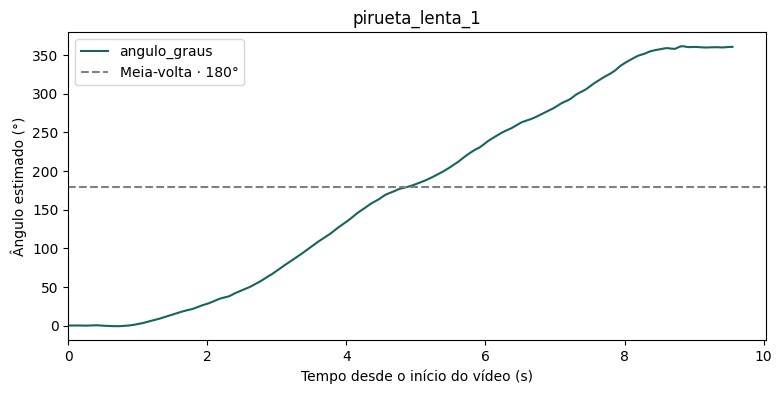

In [3]:
ROTA = "pirueta_lenta_1"
curva = curva_angulo_video(ROTA, PASTA_COLETA)

ax = curva.plot(
    x="tempo_video_s",
    y="angulo_graus",
    figsize=(9, 4),
    color="#17635e",
    legend=False,
)
ax.axhline(180, color="gray", linestyle="--", label="Meia-volta · 180°")
ax.set(
    title=ROTA,
    xlabel="Tempo desde o início do vídeo (s)",
    ylabel="Ângulo estimado (°)",
)
ax.set_xlim(left=0)
ax.legend()
plt.show()

In [4]:
from google.colab import files

curva.to_json(
    "pirueta-lenta.json",
    orient="records",
    double_precision=6,
)
files.download("pirueta-lenta.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 2. Da velocidade ao ângulo

Se você gira **90° por segundo** durante **2 segundos**, gira **180°**. Durante
uma pirueta de verdade, a velocidade muda. Para estimar o ângulo, calculamos o
giro em cada pequeno intervalo e somamos esses giros desde a primeira amostra.

A análise anterior encontrou o sinal mais forte no **eixo Y do celular**. Vamos
usar essa componente do giroscópio e adotar o sentido predominante da coleta como
positivo. Uma velocidade negativa no gráfico representa um giro no sentido oposto
ao redor desse eixo. A curva é uma **estimativa da rotação do celular pelo eixo Y**.
Se ele inclinar ou mudar de posição na mão, a estimativa pode se afastar da
rotação do corpo.

O código usa os intervalos reais entre amostras e assume que o SideSeeing
preserva a unidade do [giroscópio do Android](https://developer.android.com/reference/android/hardware/SensorEvent),
em radianos por segundo.

In [5]:
piruetas = {}

for ritmo in ritmos:
    for repeticao in (1, 2, 3):
        pastas = [
            pasta for pasta in PASTA_COLETA.glob(f"*_pirueta_{ritmo}_{repeticao}")
            if pasta.is_dir()
        ]
        if len(pastas) != 1:
            raise ValueError(
                f"Esperava uma pasta para {ritmos[ritmo].lower()} {repeticao}, "
                f"mas encontrei {len(pastas)}."
            )

        arquivo = pastas[0] / "sensors.three.uncalibrated.csv"
        colunas = ["timestamp_nano", "axis_y", "delta_y"]
        sensores = pd.read_csv(arquivo, usecols=["name", *colunas])
        giro = sensores.loc[sensores["name"].eq("uncali_gyro"), colunas]
        giro = giro.apply(pd.to_numeric, errors="coerce")
        giro = (
            giro.replace([np.inf, -np.inf], np.nan)
            .dropna()
            .groupby("timestamp_nano")
            .mean()
        )
        if len(giro) < 2:
            raise ValueError(f"Menos de duas amostras válidas em {arquivo}.")

        tempo_ns = giro.index.to_numpy()
        tempo_s = (tempo_ns - tempo_ns[0]) / 1e9

        # Subtrai o desvio estimado e adota o sentido predominante como positivo.
        velocidade = np.rad2deg((giro["delta_y"] - giro["axis_y"]).to_numpy())
        velocidade_media = (velocidade[1:] + velocidade[:-1]) / 2
        giro_por_intervalo = velocidade_media * np.diff(tempo_s)
        angulo = np.r_[0, np.cumsum(giro_por_intervalo)]

        piruetas[ritmo, repeticao] = pd.DataFrame({
            "tempo_s": tempo_s,
            "velocidade_graus_s": velocidade,
            "angulo_graus": angulo,
        })

print(f"{len(piruetas)} gravações carregadas.")

9 gravações carregadas.


### 3. Comparar os três ritmos

No gráfico de cima, procure os momentos em que o giro ficou mais rápido. No de
baixo, veja como o ângulo se aproxima de um quarto, meia ou uma volta inteira.
Troque `REPETICAO` para ver outra tentativa de cada ritmo. O tempo começa na
primeira amostra válida do giroscópio e pode incluir instantes antes e depois da
pirueta.

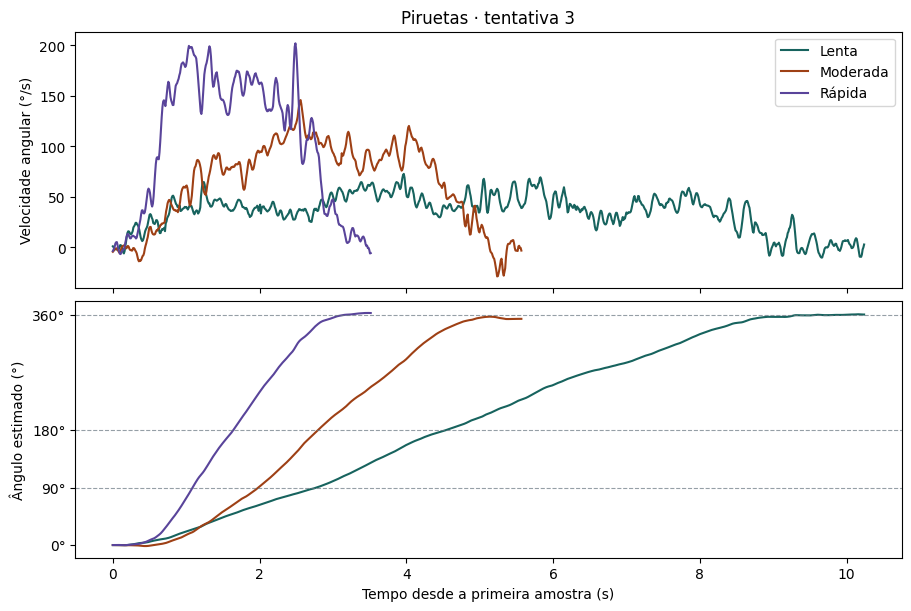

,Ritmo,Tentativa,Ângulo ao fim do registro (°),Maior velocidade em módulo (°/s)
0,Lenta,1,360.7,84.4
1,Lenta,2,352.0,69.0
2,Lenta,3,361.1,72.8
3,Moderada,1,371.4,115.1
4,Moderada,2,373.3,121.4
5,Moderada,3,354.3,145.9
6,Rápida,1,362.7,279.3
7,Rápida,2,350.5,230.5
8,Rápida,3,363.4,202.2


In [6]:
REPETICAO = 3  # Escolha 1, 2 ou 3.

fig, (ax_vel, ax_giro) = plt.subplots(
    2, 1, figsize=(9, 6), sharex=True, layout="constrained"
)

for (ritmo, rotulo), cor in zip(ritmos.items(), ("#17635e", "#9e4015", "#59449a")):
    dados = piruetas[ritmo, REPETICAO]
    ax_vel.plot(dados["tempo_s"], dados["velocidade_graus_s"], color=cor, label=rotulo)
    ax_giro.plot(dados["tempo_s"], dados["angulo_graus"], color=cor)

for graus in (90, 180, 360):
    ax_giro.axhline(graus, color="#687680", linestyle="--", linewidth=0.8, alpha=0.7)

ax_giro.set_yticks([0, 90, 180, 360], ["0°", "90°", "180°", "360°"])
ax_vel.set_title(f"Piruetas · tentativa {REPETICAO}")
ax_vel.set_ylabel("Velocidade angular (°/s)")
ax_vel.legend()
ax_giro.set_ylabel("Ângulo estimado (°)")
ax_giro.set_xlabel("Tempo desde a primeira amostra (s)")
plt.show()

resumo = pd.DataFrame([
    {
        "Ritmo": ritmos[ritmo],
        "Tentativa": repeticao,
        "Ângulo ao fim do registro (°)": dados["angulo_graus"].iloc[-1],
        "Maior velocidade em módulo (°/s)": dados["velocidade_graus_s"].abs().max(),
    }
    for (ritmo, repeticao), dados in piruetas.items()
])
display(resumo.round(1))

### Do notebook para o site · Pause a pirueta

1. Antes de olhar os gráficos, aponte para frente. Para onde você apontaria
   depois de 90°, 180° e 360° de giro?
2. Em qual ritmo a curva do ângulo sobe mais depressa? Como aparece esse
   momento no gráfico de velocidade?
3. Compare as três tentativas. Se o ângulo final ficar longe de 360°, reveja
   o vídeo e observe como o celular foi segurado ao longo do movimento.

**Primeira interação para o site:** uma seta parte de 0°. A pessoa escolhe uma
gravação e arrasta o controle de tempo para ver a seta acompanhar o ângulo
estimado. O desafio é pausar quando ela chegar perto de 90°, 180° e 360°.

In [7]:
from google.colab import drive

drive.flush_and_unmount()